# Logistic map: bifurcation and Lyapunov exponent

The map $x_{n+1} = r x_n (1 - x_n)$ on $r \in [2.4, 4.0]$. A bifurcation
diagram (post-transient iterates) exposes period doubling and the chaotic
window; the Lyapunov exponent $\lambda(r)$ crosses zero exactly where
chaos begins.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)

## 1. Bifurcation diagram

For each $r$, iterate 1 000 steps to kill the transient, then record the
next 100. Plot those as a dot cloud over $r$.

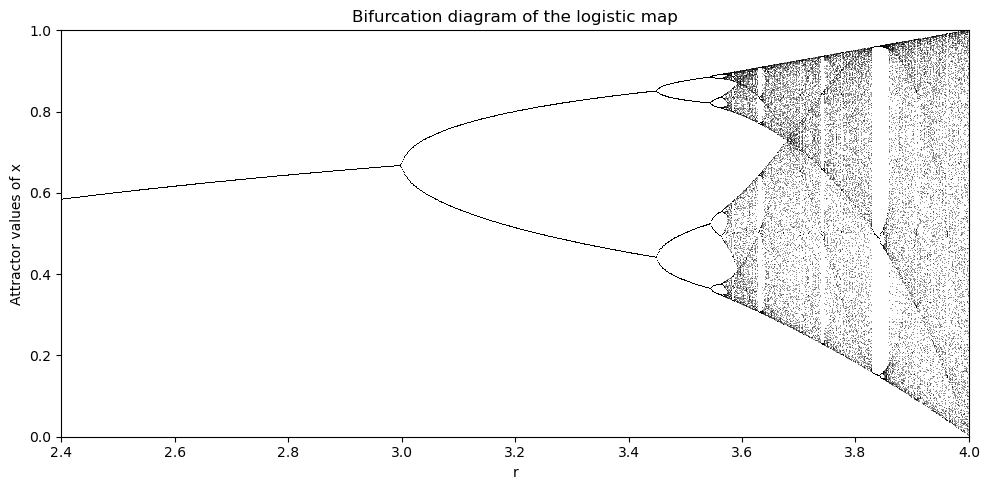

In [2]:
n_r = 1200
r_grid = np.linspace(2.4, 4.0, n_r)
n_transient = 1000
n_record = 100

x = 0.5 * np.ones(n_r)
for _ in range(n_transient):
    x = r_grid * x * (1 - x)

records = np.empty((n_record, n_r))
for k in range(n_record):
    x = r_grid * x * (1 - x)
    records[k] = x

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(np.repeat(r_grid[None, :], n_record, axis=0), records,
        ",", color="black", alpha=0.4)
ax.set_xlim(r_grid.min(), r_grid.max())
ax.set_ylim(0, 1)
ax.set_xlabel("r")
ax.set_ylabel("Attractor values of x")
ax.set_title("Bifurcation diagram of the logistic map")
plt.tight_layout()
plt.show()

Key landmarks: period-1 fixed point splits to period-2 at $r = 3$;
period-4 at $r \approx 3.449$; onset of chaos near the Feigenbaum point
$r_\infty \approx 3.56995$; a famous period-3 window around $r \approx 3.828$.

## 2. Lyapunov exponent

$$\lambda(r) = \lim_{N \to \infty} \frac{1}{N} \sum_{n=0}^{N-1} \ln |f'(x_n)|, \qquad
  f'(x) = r (1 - 2 x).$$

Chaos corresponds to $\lambda > 0$; periodic attractors give $\lambda < 0$,
with $\lambda \to -\infty$ at superstable cycles where $f'(x_n) = 0$ for
some orbit point.

In [3]:
n_lyap = 10_000
x = 0.5 * np.ones(n_r)
# Burn-in
for _ in range(1000):
    x = r_grid * x * (1 - x)

lyap = np.zeros(n_r)
for _ in range(n_lyap):
    x = r_grid * x * (1 - x)
    # Guard against |1 - 2x| == 0 exactly
    lyap += np.log(np.abs(r_grid * (1 - 2 * x)) + 1e-300)
lyap /= n_lyap

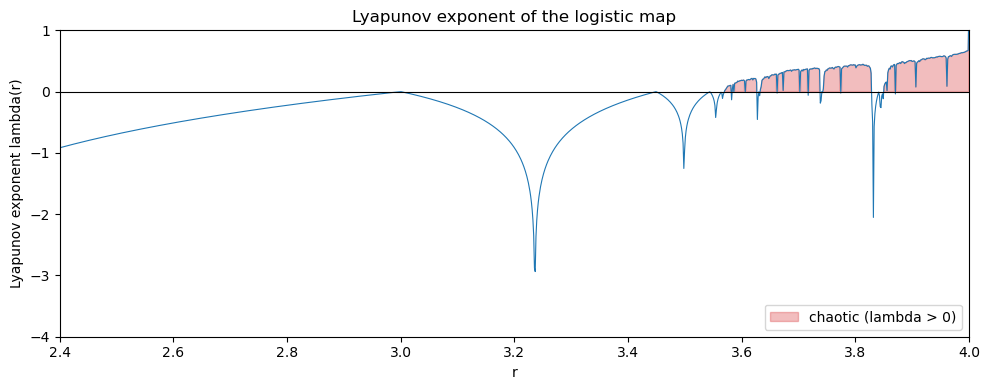

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(r_grid, lyap, lw=0.8, color="tab:blue")
ax.axhline(0, color="black", lw=0.8)
ax.fill_between(r_grid, 0, lyap, where=(lyap > 0),
                color="tab:red", alpha=0.3, label="chaotic (lambda > 0)")
ax.set_xlim(r_grid.min(), r_grid.max())
ax.set_ylim(-4, 1)
ax.set_xlabel("r")
ax.set_ylabel("Lyapunov exponent lambda(r)")
ax.set_title("Lyapunov exponent of the logistic map")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Exercises

1. Zoom into the period-3 window near $r = 3.828$. Produce a bifurcation
   sub-plot on $r \in [3.82, 3.86]$ with 400 recorded iterates per $r$.
2. Estimate the Feigenbaum constant
   $\delta = \lim_{n \to \infty} (r_n - r_{n-1}) / (r_{n+1} - r_n) \approx 4.669$
   from the first three period-doubling thresholds.
3. Replace $x(1-x)$ with the sine map $\sin(\pi x)$ (rescaled). Produce the
   analogous bifurcation diagram and compare the geometry to the logistic
   case.